# Notebook 03: análisis exploratorio

*Usar IA sin estar convencido: discrepancia entre uso y actitud en desarrolladores de software.* Trabajo final de especialización, Maestría en Explotación de Datos y Descubrimiento del Conocimiento, FCEyN-UBA.

Análisis exploratorio del trabajo, con la lógica de `scripts/eda.py`, `scripts/temporal.py` y `scripts/brecha_uso_actitud.py`:

- **H1:** la discrepancia entre uso y actitud crece con la experiencia.
- **H2:** la discrepancia varía según el rol.
- **Sin hipótesis previa:** variación por año, grupos de perfiles (K-Means) y brecha entre uso y actitud en toda la población.

H1, H2, la variación por año y los grupos usan los 80.369 usuarios de IA. La brecha en toda la población usa los 154.911 desarrolladores.

## 1. Preparación

In [1]:
import sys
import importlib.util
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

def load_module(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod

eda = load_module("eda", ROOT / "scripts" / "eda.py")
temporal = load_module("temporal", ROOT / "scripts" / "temporal.py")
brecha = load_module("brecha_uso_actitud", ROOT / "scripts" / "brecha_uso_actitud.py")

plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
print(f"Etiquetas de la variable a predecir: {eda.TARGET_LABELS}")

Etiquetas de la variable a predecir: {1: 'Sin discrepancia', 0: 'Con discrepancia uso-actitud'}


## 2. Carga de los datos

In [2]:
df_full = pd.read_parquet(ROOT / "data" / "df_clean.parquet")
df_users = pd.read_parquet(ROOT / "data" / "df_clean_users.parquet")

print(f"Todos:    {df_full.shape}, sin discrepancia {df_full['target'].mean():.1%}")
print(f"Usuarios: {df_users.shape}, sin discrepancia {df_users['target'].mean():.1%}")

Todos:    (154911, 91), sin discrepancia 40.7%
Usuarios: (80369, 99), sin discrepancia 78.5%


## 3. H1: experiencia acumulada

Se esperaba que la discrepancia (valor 0 de la variable a predecir) aumentara con los años programando. Se usan los años programando porque la pregunta de experiencia profesional no existe en la edición 2025.

In [3]:
tabla_h1_users, r_users, p_users = eda.h1_seniority(df_users.assign(discrepancia=1 - df_users["target"]))
print(f"\nCorrelación punto-biserial: r = {r_users:.4f}, p = {p_users:.2e}\n")
tabla_h1_users

Guardado outputs/usuarios_experiencia.png (r=0.035, p=3.60e-23)
  global: creciente (de 18.4% a 23.4%, diferencia +5.0 puntos)
  2023: no creciente (de 15.2% a 16.3%, diferencia +1.1 puntos)
  2024: no creciente (de 22.8% a 24.8%, diferencia +2.0 puntos)
  2025: creciente (de 20.0% a 28.2%, diferencia +8.2 puntos)

Correlación punto-biserial: r = 0.0350, p = 3.60e-23



,global,2023,2024,2025
exp_tramo,,,,
0–2,18.4,15.2,22.8,20.0
3–5,19.4,14.7,21.9,26.0
6–10,20.4,14.5,22.7,27.3
11–20,22.4,16.0,24.0,27.8
>20,23.4,16.3,24.8,28.2


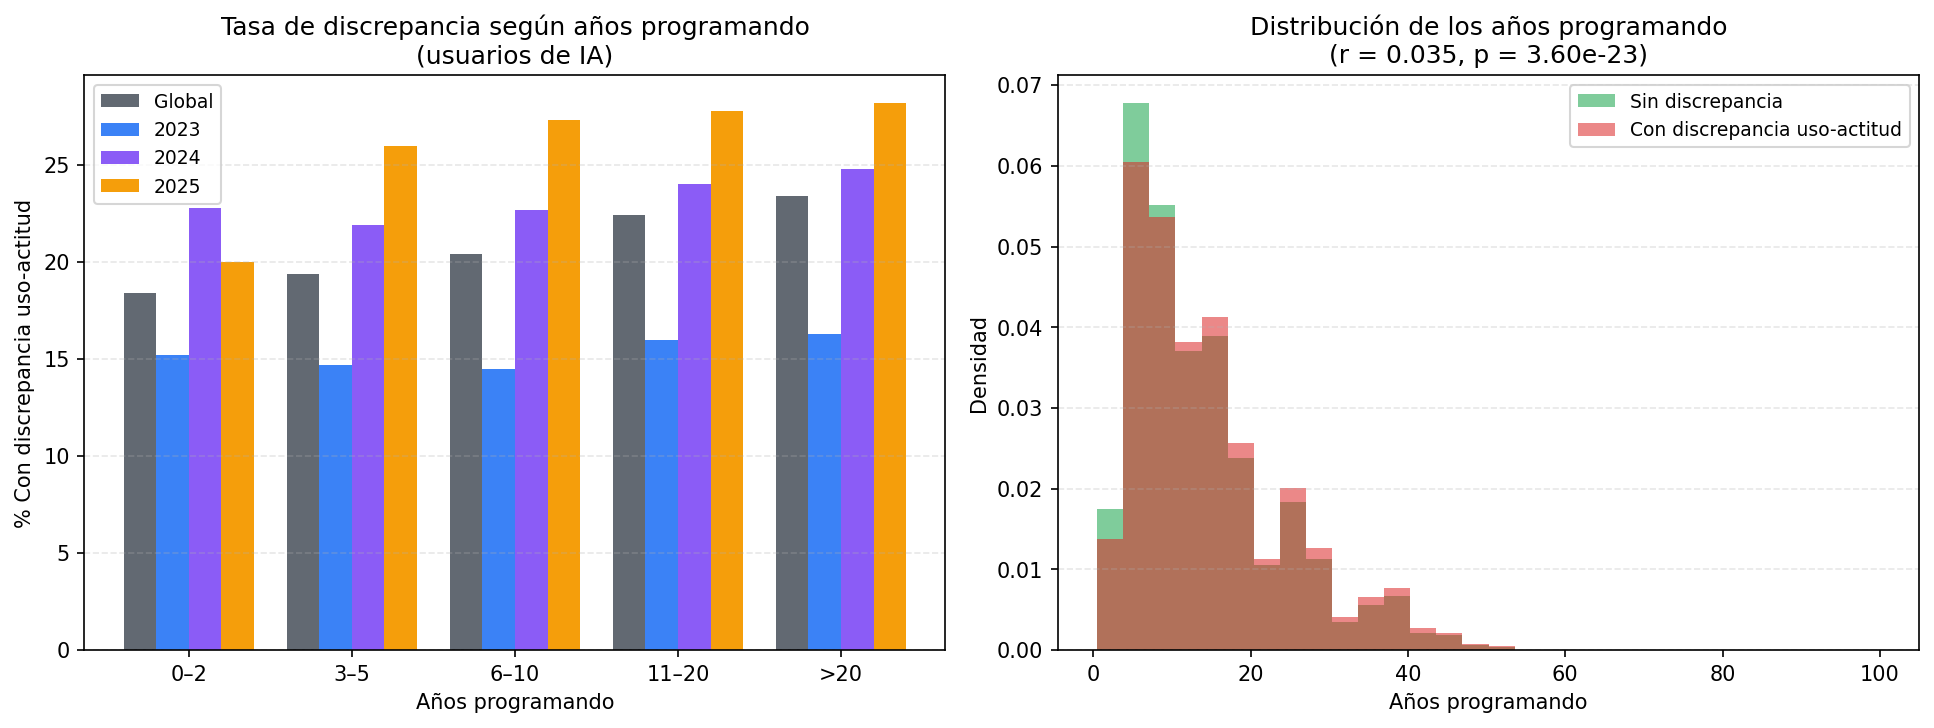

In [4]:
display(Image(filename=str(ROOT / "outputs" / "usuarios_experiencia.png")))

**Lectura.** Entre usuarios de IA la correlación entre años programando y discrepancia es débil (r = 0,035). La diferencia entre quienes programan hace 0 a 2 años y más de 20 años es de 5,0 puntos porcentuales, mucho menor que en el conjunto completo (r = 0,108). Con esta muestra el valor de p es muy bajo, pero r explica alrededor del 0,1 % de la varianza.

### 3.1 H1 por año, entre usuarios

  H1 global: creciente (de 18.4% a 23.4%, diferencia +5.0 puntos)
  H1 2023: no creciente (de 15.2% a 16.3%, diferencia +1.1 puntos)
  H1 2024: no creciente (de 22.8% a 24.8%, diferencia +2.0 puntos)
  H1 2025: creciente (de 20.0% a 28.2%, diferencia +8.2 puntos)


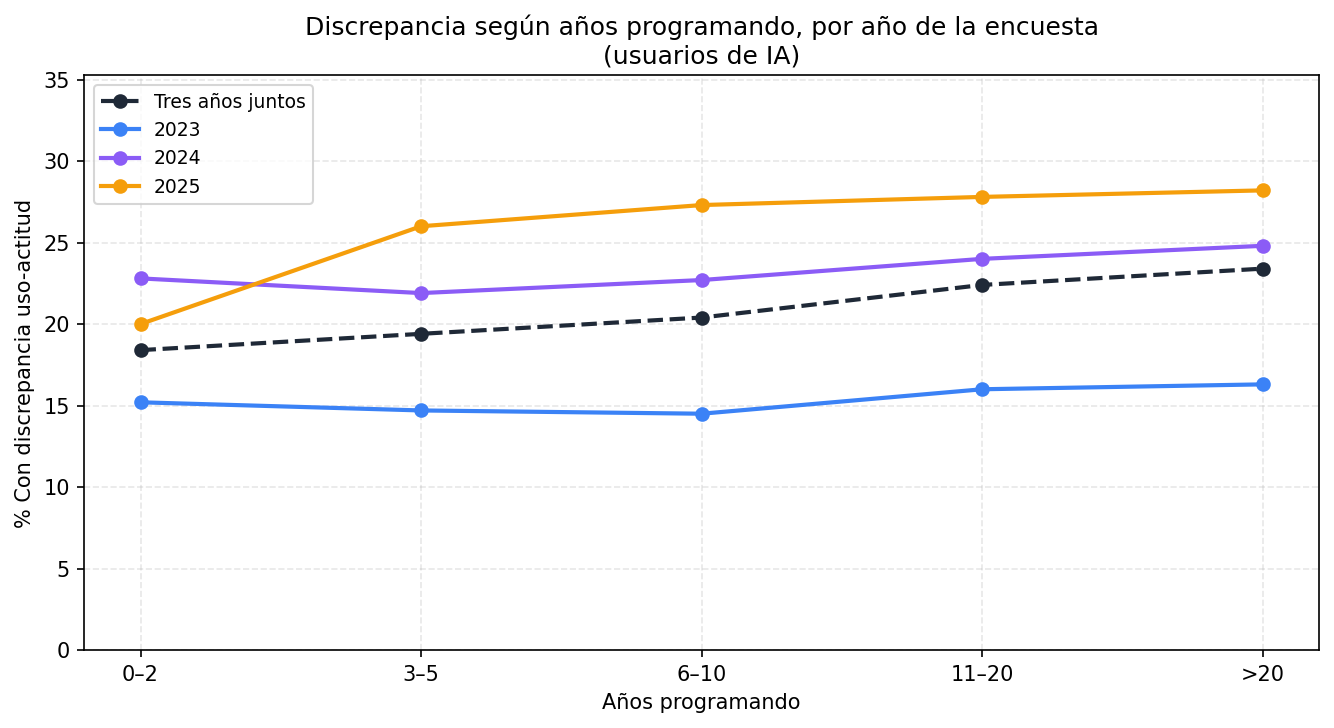

,global,2023,2024,2025
exp_tramo,,,,
0–2,18.4,15.2,22.8,20.0
3–5,19.4,14.7,21.9,26.0
6–10,20.4,14.5,22.7,27.3
11–20,22.4,16.0,24.0,27.8
>20,23.4,16.3,24.8,28.2


In [5]:
df_disc = df_users.assign(discrepancia=1 - df_users["target"])
tabla_base, fig_base = temporal.tasa_base_por_anio(df_disc)
tabla_h1, fig_h1 = temporal.h1_temporal_usuarios(df_disc)
fig_base.savefig(ROOT / "outputs" / "temporal_tasa_discrepancia.png", dpi=150, bbox_inches="tight")
fig_h1.savefig(ROOT / "outputs" / "temporal_experiencia.png", dpi=150, bbox_inches="tight")
display(Image(filename=str(ROOT / "outputs" / "temporal_experiencia.png")))
tabla_h1

**Lectura.** La diferencia entre el tramo de menor y el de mayor experiencia es chica en 2023 (+1,1 puntos) y en 2024 (+2,0), y solo es marcada en 2025 (+8,2).

## 4. H2: tipo de rol

Se esperaba una discrepancia mayor en los roles con salidas más fáciles de verificar.

In [6]:
df_h2, tasa_global = eda.h2_devtype(df_users.assign(discrepancia=1 - df_users["target"]))
print(f"Tasa de discrepancia entre usuarios: {tasa_global:.1f} %\n")
df_h2.head(10).round(1)

Guardado outputs/usuarios_rol.png
Tasa de discrepancia entre usuarios: 21.5 %



,devtype,tasa,n
1,Data scientist or machine learning specialist,15.1,1955
6,"Developer, front-end",18.4,5641
9,Engineering manager,18.5,1765
0,Data engineer,18.6,1489
8,"Developer, mobile",20.3,3115
7,"Developer, full-stack",20.9,30281
10,Other,21.1,12206
2,DevOps specialist,22.1,1400
3,"Developer, back-end",23.2,14981
11,Other (please specify):,25.0,1595


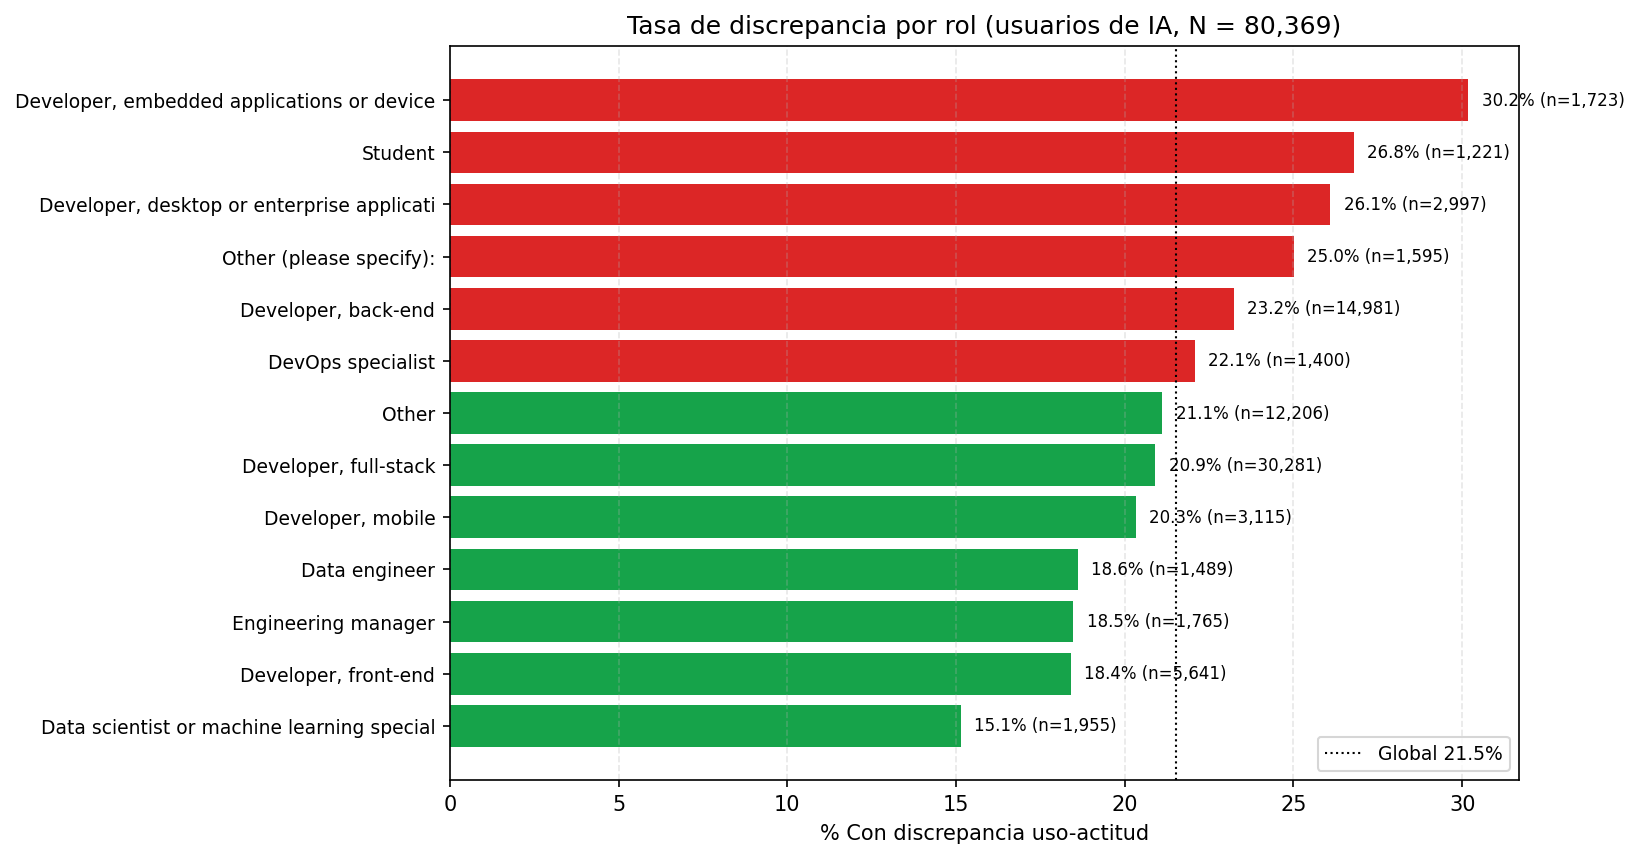

In [7]:
display(Image(filename=str(ROOT / "outputs" / "usuarios_rol.png")))

**Lectura.** Sistemas embebidos (30,2 %), estudiantes (26,8 %) y aplicaciones de escritorio o empresariales (26,1 %) tienen las tasas más altas. Ciencia de datos y aprendizaje automático tiene la más baja. En el conjunto completo embebidos y escritorio también están arriba, pero los estudiantes quedan por debajo de la media, así que el resultado apoya la hipótesis solo en parte.

### 4.1 H2 por año, entre usuarios

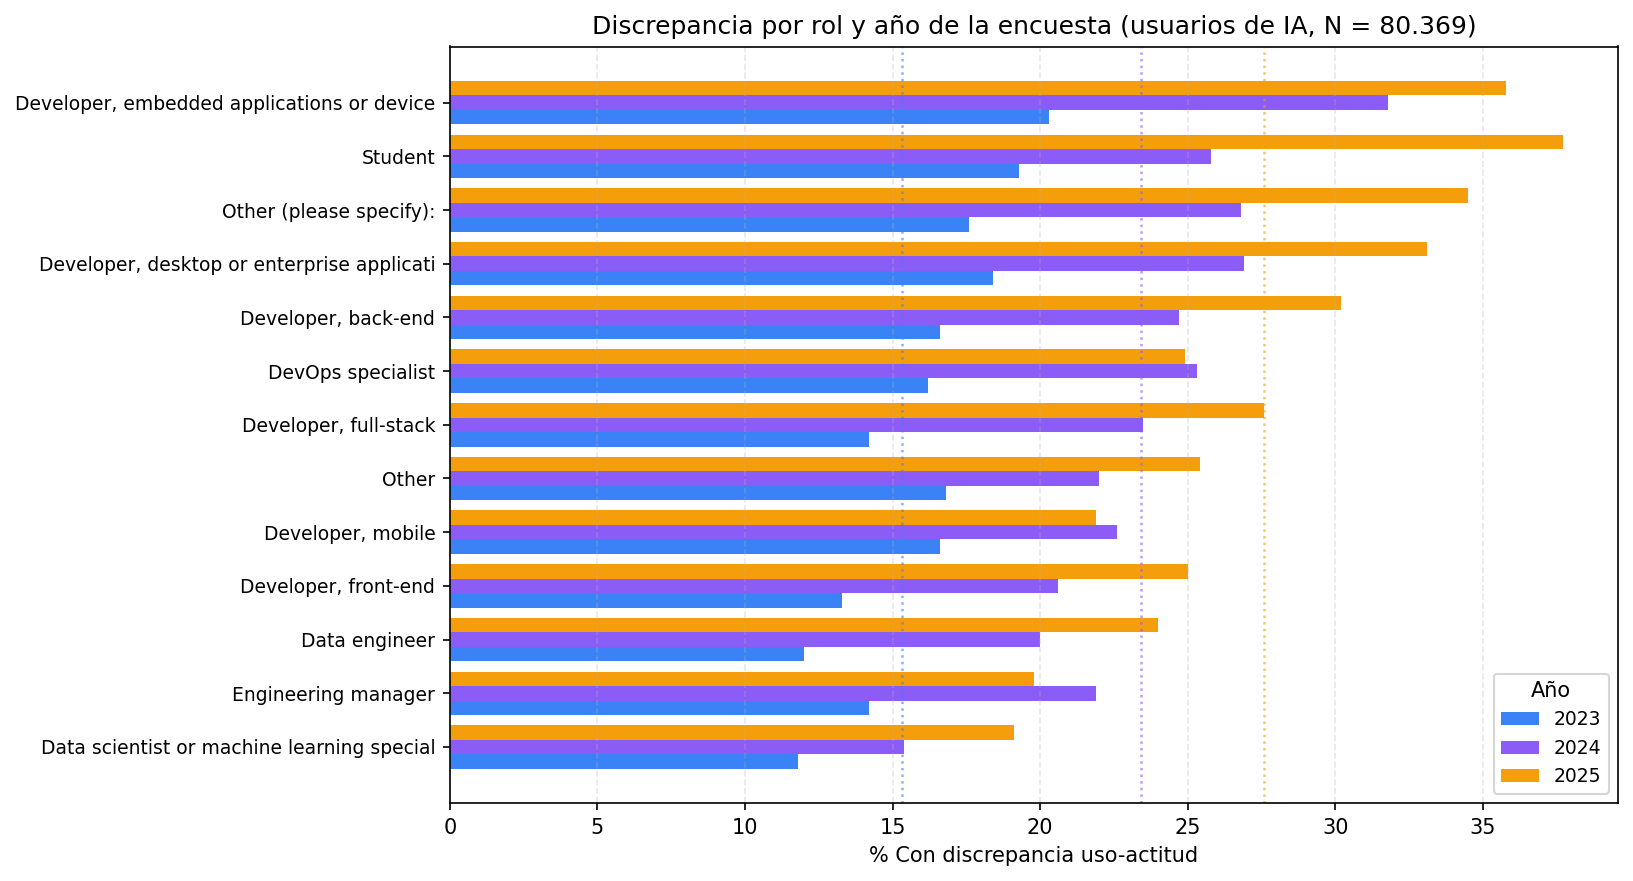

In [8]:
tabla_h2, fig_h2 = temporal.h2_temporal_usuarios(df_disc)
fig_h2.savefig(ROOT / "outputs" / "temporal_rol.png", dpi=150, bbox_inches="tight")
display(Image(filename=str(ROOT / "outputs" / "temporal_rol.png")))

**Lectura.** El orden de los roles cambia entre años: embebidos tiene la tasa más alta en 2023 y 2024, y en 2025 los estudiantes pasan al primer lugar.

## 5. Variación de la discrepancia por año

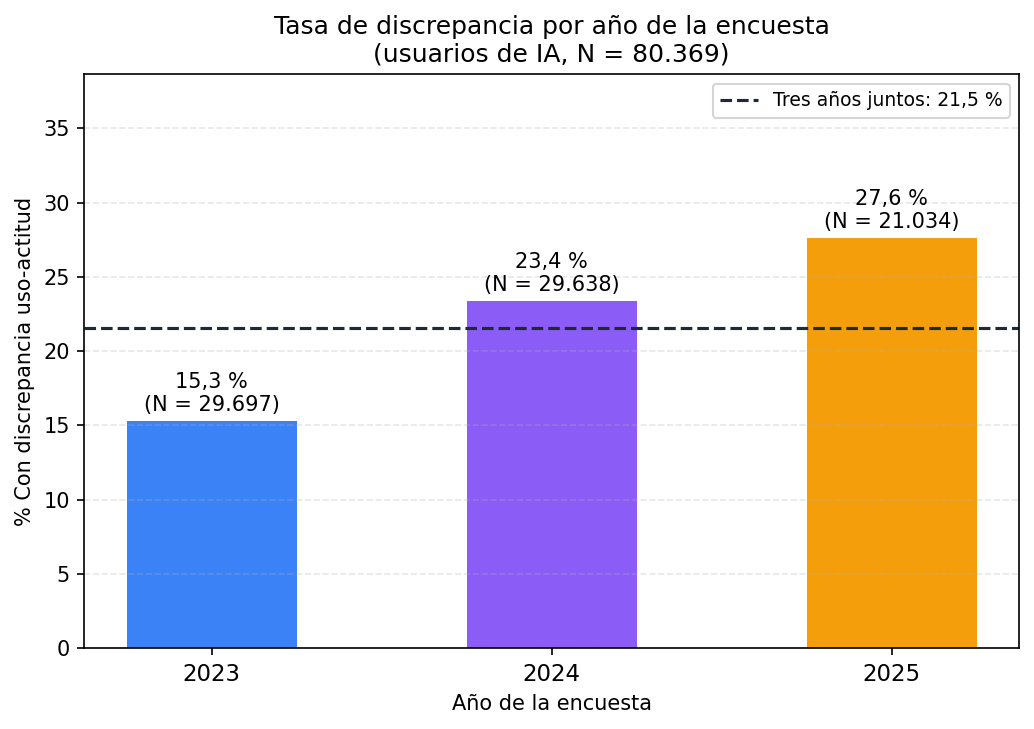

,tasa_pct,n_total,n_disc
survey_year,,,
2023,15.3,29697,4553
2024,23.4,29638,6943
2025,27.6,21034,5799


In [9]:
display(Image(filename=str(ROOT / "outputs" / "temporal_tasa_discrepancia.png")))
tabla_base

**Lectura.** La tasa de discrepancia entre usuarios sube de 15,3 % en 2023 a 23,4 % en 2024 y a 27,6 % en 2025. El aumento de 2023 a 2024 (+8,1 puntos) es el doble que el de 2024 a 2025 (+4,1), así que el crecimiento se desacelera.

## 6. Segmentación de perfiles (K-Means, k = 4)

Análisis descriptivo, sin hipótesis previa. k = 4 se fijó por interpretabilidad; el índice de silueta es bajo para cualquier k (0,20 con k = 2, 0,21 con k = 3 y 0,19 con k = 4). Los grupos se numeran de menor a mayor mediana de años programando.

In [10]:
df_clust_users, tabla_h4_users = eda.h4_clusters(df_users.assign(discrepancia=1 - df_users["target"]))
tabla_h4_users

  Variables de la segmentación: ['YearsCode', 'WorkExp', 'EdLevel', 'OrgSize', 'lang_count', 'db_count', 'plat_count', 'env_count']


Guardado outputs/usuarios_grupos.png


,% de usuarios,% discrepancia,Experiencia mediana
cluster,,,
Grupo 1,15.2,22.2,8.0
Grupo 2,49.2,21.2,10.0
Grupo 3,19.5,20.1,10.0
Grupo 4,16.2,23.7,30.0


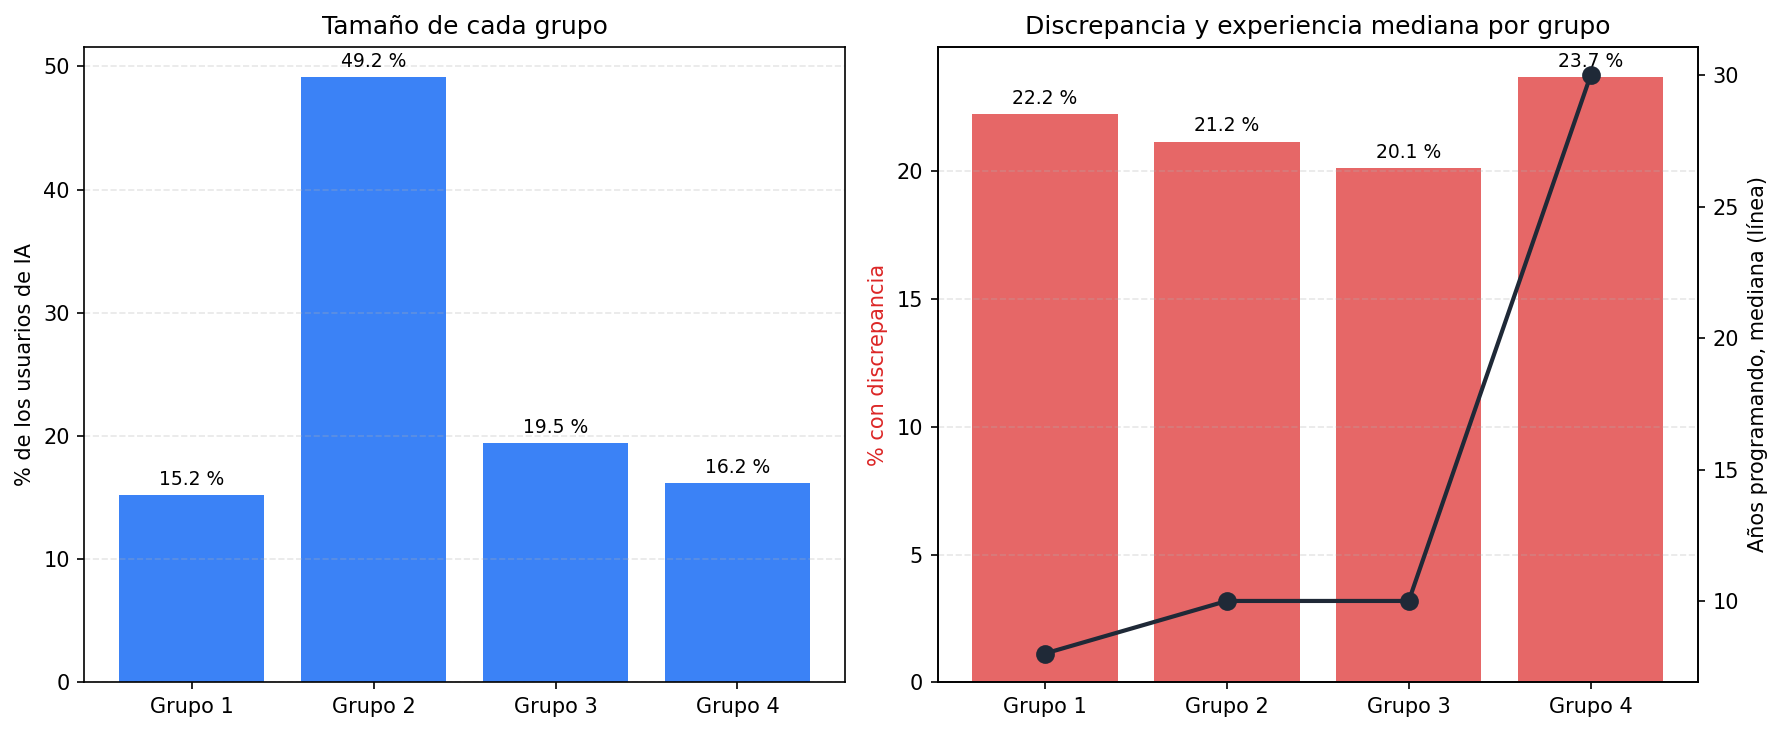

In [11]:
display(Image(filename=str(ROOT / "outputs" / "usuarios_grupos.png")))

**Lectura.** El grupo 1 (15,2 %) reúne a quienes no tienen título universitario y llevan menos años programando. El grupo 2 (49,2 %) tiene título universitario y un stack acotado. El grupo 3 (19,5 %) usa la mayor variedad de herramientas, y el grupo 4 (16,2 %) es el más senior, con una mediana de 30 años programando. La discrepancia va de 20,1 % a 23,7 %, así que no hay diferencias importantes entre los grupos. El grupo 4 tiene además más respuestas de 2025 (45 %).

## 7. Brecha entre uso y actitud en toda la población

Se cruzan la pregunta de uso de IA y la de actitud en cuatro grupos. Necesita usuarios y no usuarios, por eso usa todos los desarrolladores profesionales que respondieron ambas preguntas.

In [12]:
df_brecha = brecha.cargar()
print(f"N = {len(df_brecha):,}\n")
print("Distribución global (%):")
print((df_brecha["grupo"].value_counts(normalize=True) * 100).round(1))
print("\nPor año (%):")
print((df_brecha.groupby("survey_year")["grupo"].value_counts(normalize=True) * 100).unstack().round(1))

N = 108,508

Distribución global (%):
grupo
Usa y actitud favorable          58.1
Usa sin actitud favorable        15.6
No usa, sin actitud favorable    13.2
No usa, actitud favorable        13.1
Name: proportion, dtype: float64

Por año (%):
grupo        No usa, actitud favorable  No usa, sin actitud favorable  \
survey_year                                                             
2023                              22.5                           14.3   
2024                               8.5                            8.9   
2025                               2.2                           17.0   

grupo        Usa sin actitud favorable  Usa y actitud favorable  
survey_year                                                      
2023                               9.6                     53.6  
2024                              19.2                     63.5  
2025                              21.8                     59.0  


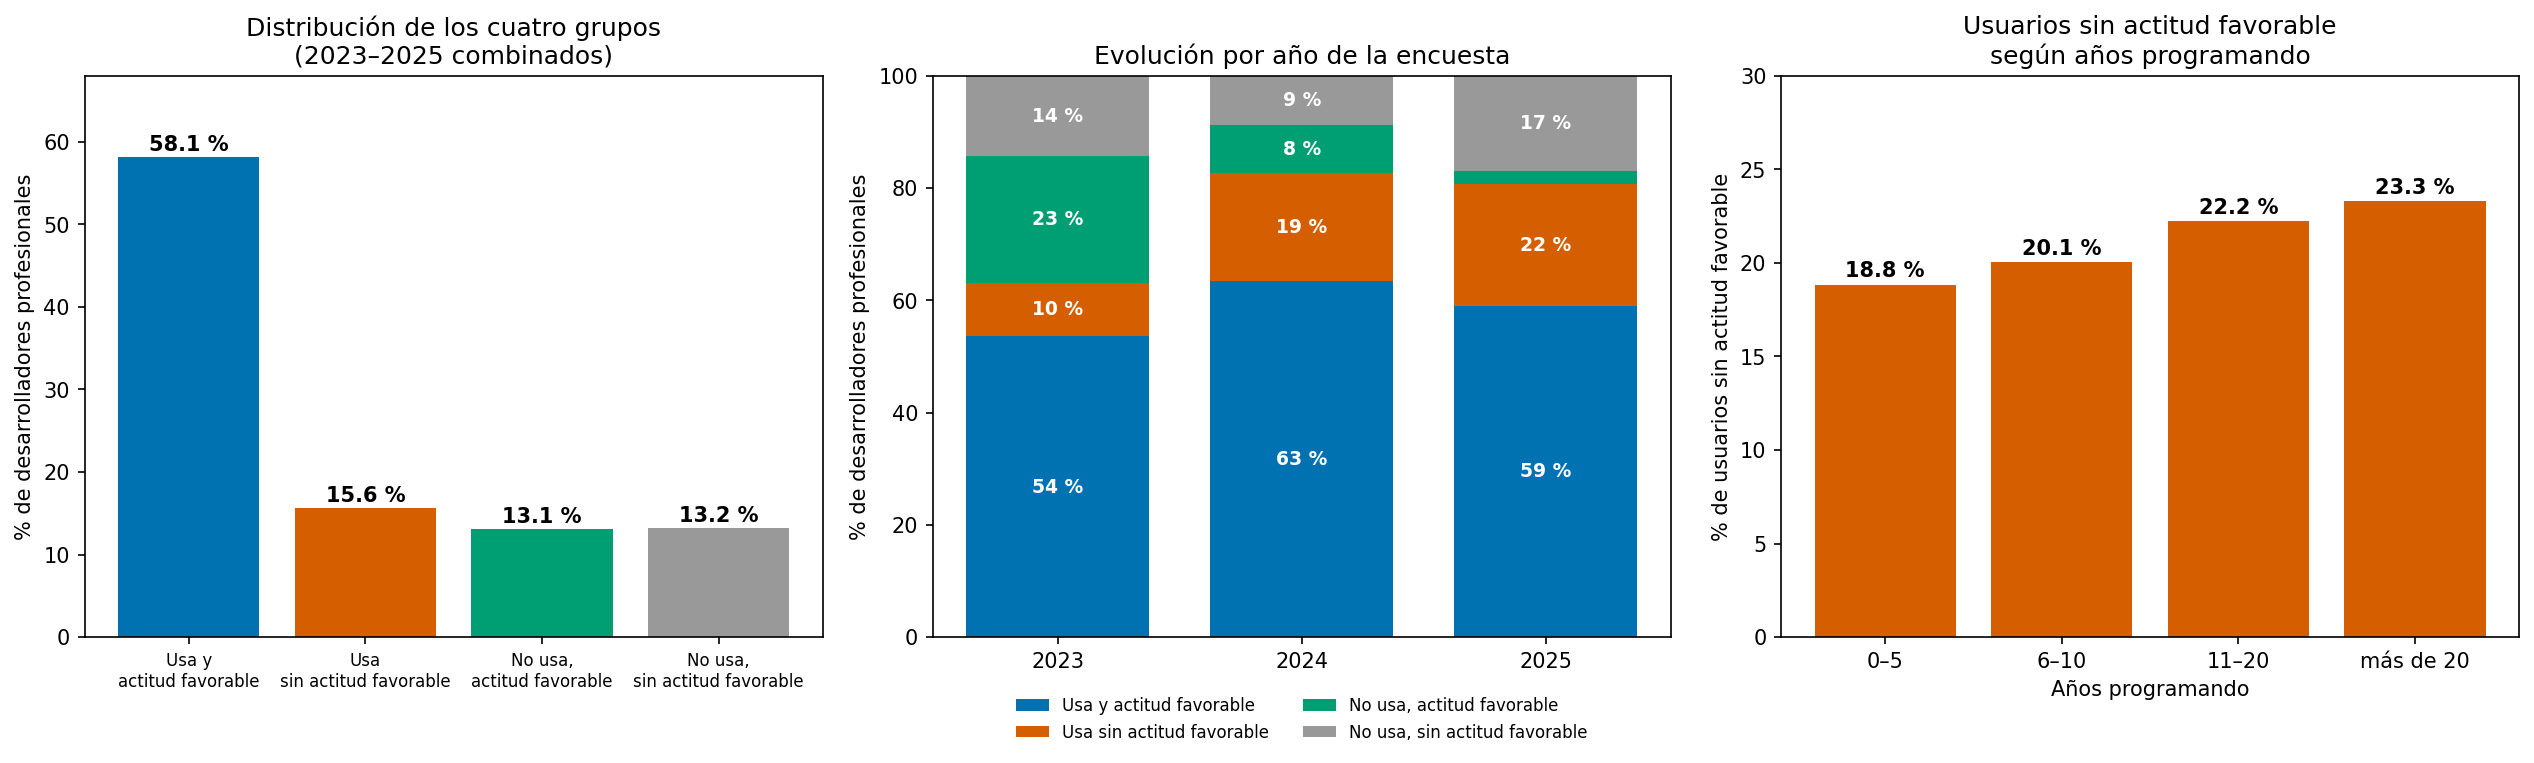

In [13]:
fig_brecha = brecha.figura(df_brecha)
fig_brecha.savefig(ROOT / "outputs" / "brecha_uso_actitud.png", dpi=150, bbox_inches="tight")
display(Image(filename=str(ROOT / "outputs" / "brecha_uso_actitud.png")))

**Lectura.**
- El 58,1 % usa IA y tiene una actitud favorable, y el 15,6 % usa IA sin actitud favorable (la discrepancia que estudia el trabajo).
- Entre los no usuarios, la actitud favorable cae de 61 % en 2023 a 12 % en 2025.
- Entre los usuarios, la falta de actitud favorable sube de 15 % a 27 %.
- Con muestras independientes no se puede distinguir si cambió la actitud de las personas o quiénes responden la encuesta.

## 8. Próximo paso

`notebooks/04_modelado.ipynb`: modelado supervisado, SHAP y análisis temporal.